In [2]:
from pca_utils import *

# Import data

In [3]:
path1 = "/mnt/c/users/helen/Desktop/190226/WT/foci15/aggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226/MGS3/foci15/aggregated_data.csv"

In [4]:
df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)

In [5]:
df1["sample"] = "WT"
df2["sample"] = "MGS3"

combined_df = pd.concat(
    [df1, df2],
    ignore_index=True
)

In [6]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 59


In [7]:
combined_df.tail()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample
54,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_19)_ROI_...,42,25.5,5.695568,0.810868,0.696154,21.553301,31.478009,46.0,25.0,MGS3
55,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_20)_ROI_...,24,30.0,6.180387,0.721552,0.804000,19.503048,38.290739,58.5,28.0,MGS3
56,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_21)_ROI_...,51,32.0,6.383076,0.630985,0.789474,22.071068,42.222221,61.0,31.0,MGS3
57,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_22)_ROI_...,36,37.0,6.863663,0.740591,0.740741,25.778175,79.250000,108.5,64.0,MGS3
58,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_23)_ROI_...,50,35.0,6.675581,0.729428,0.784238,23.710155,65.375000,90.5,52.0,MGS3


# Correlation analysis

In [8]:
# Select numerical columns
df_numeric = df.select_dtypes(include=np.number)

# Calculate Spearman correlation
corr = df_numeric.corr(method="spearman")

display(corr.round(3))

,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity
n_foci,1.000,-0.182,-0.177,0.374,-0.414,-0.125,0.001,-0.030,0.038
area,-0.182,1.000,1.000,-0.581,0.554,0.950,0.687,0.756,0.615
equivalent_diameter_area,-0.177,1.000,1.000,-0.580,0.553,0.951,0.687,0.757,0.615
eccentricity,0.374,-0.581,-0.580,1.000,-0.770,-0.476,-0.454,-0.512,-0.377
solidity,-0.414,0.554,0.553,-0.770,1.000,0.403,0.454,0.527,0.377
perimeter,-0.125,0.950,0.951,-0.476,0.403,1.000,0.591,0.654,0.525
mean_intensity,0.001,0.687,0.687,-0.454,0.454,0.591,1.000,0.986,0.985
max_intensity,-0.030,0.756,0.757,-0.512,0.527,0.654,0.986,1.000,0.952
min_intensity,0.038,0.615,0.615,-0.377,0.377,0.525,0.985,0.952,1.000


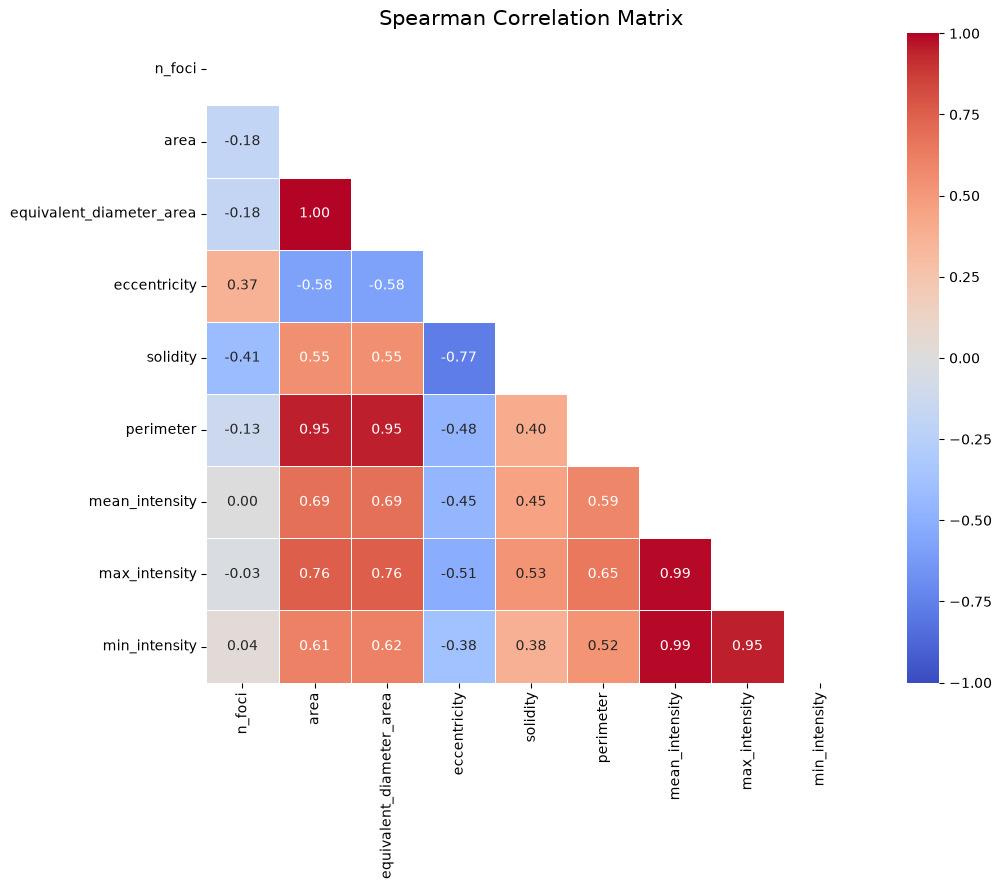

In [9]:
plt.figure(figsize=(12, 9))

# Show only lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix", fontsize=15)
plt.tight_layout()
plt.show()

## Graphs

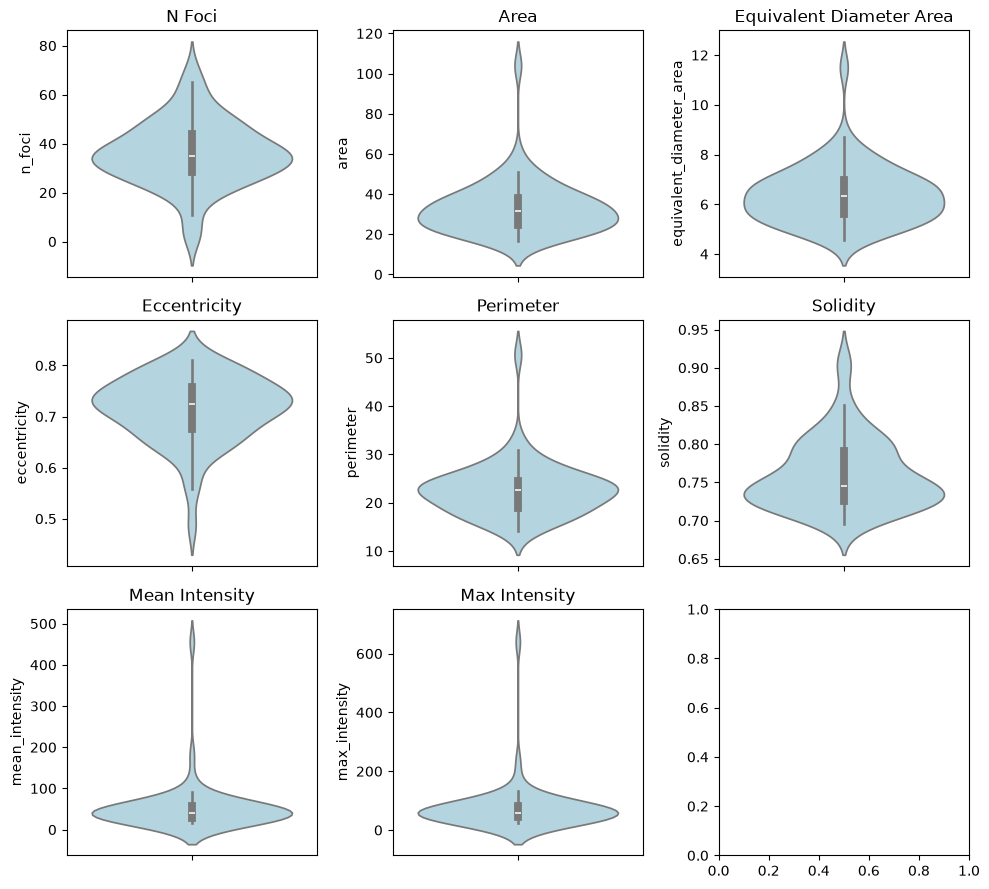

In [10]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [11]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    #"eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

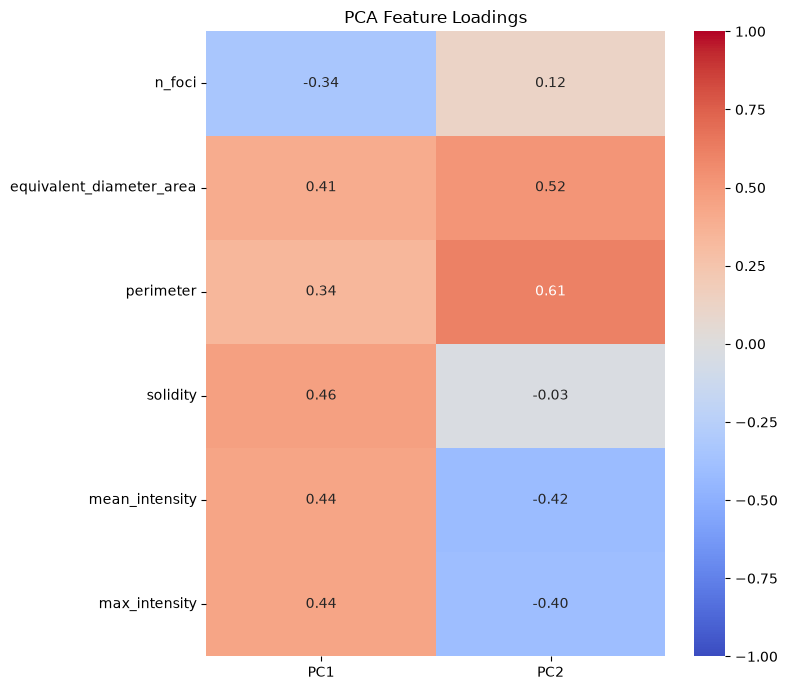

In [12]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [13]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS3    0.681494  0.023666
WT     -0.467310 -0.016228


In [14]:
#centroids = plot_pca_centroids_ci(
    #pca_df,
    #group_col="sample",
    #confidence=0.95
#)

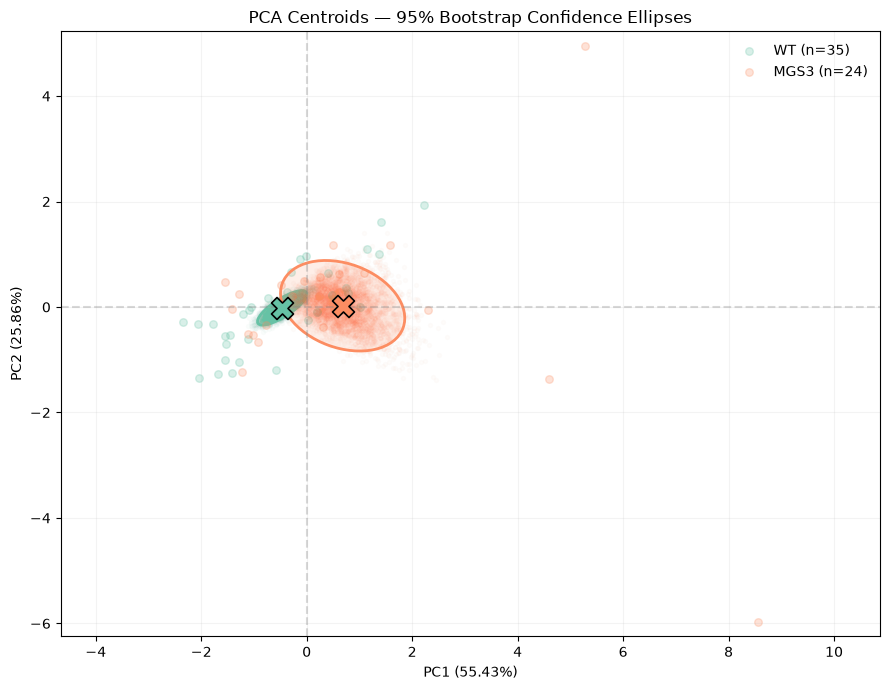

In [15]:
results_boot = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

In [16]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,3.986903,0.0152,0.065373,59,2
1,PERMDISP,2.278645,0.1435,NaN,59,2


# Detect outliers

In [17]:
pca_df_outliers = detect_pca_outliers(
    pca_df,
    group_col="sample",
    features=("PC1", "PC2"),
    confidence=0.99
)

# Display detected outliers
outliers = pca_df_outliers[
    pca_df_outliers["outlier"]
]

display(outliers)

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,PC1,PC2,mahalanobis_distance,outlier
36,C2_MP_U2OS_fixed_MGS3_001.nd2_(series_2)_ROI_0...,11,104.0,11.507255,0.559012,0.851429,50.662951,64.23333,95.0,46.0,MGS3,5.273443,4.946944,3.956676,True
42,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_05)_ROI_...,2,38.5,6.983433,0.486204,0.907313,20.899495,455.35228,640.0,321.5,MGS3,8.552641,-5.968059,4.224324,True


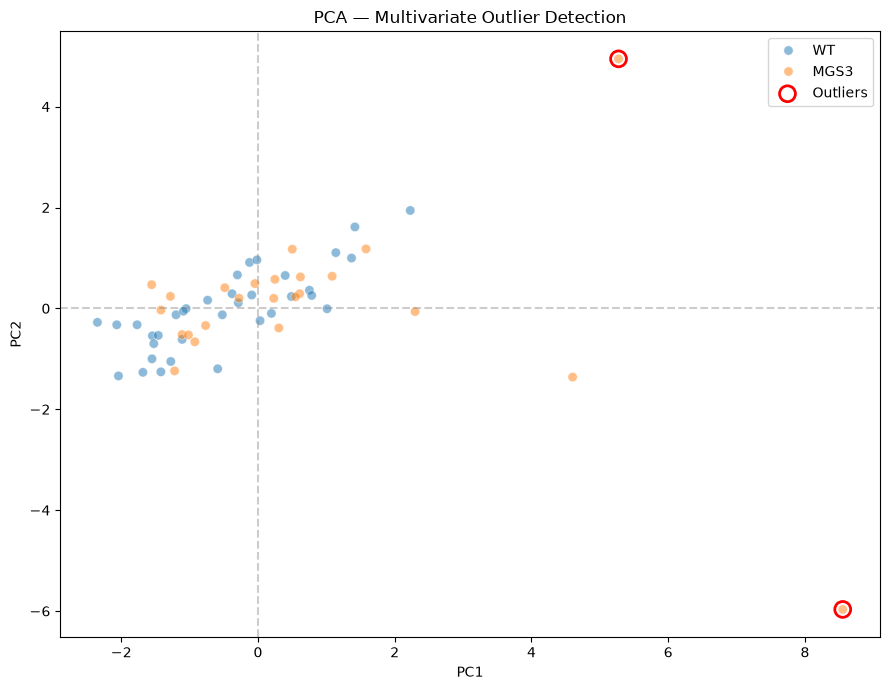

In [18]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=pca_df_outliers,
    x="PC1",
    y="PC2",
    hue="sample",
    alpha=0.5,
    s=45,
    ax=ax
)

# Highlight outliers
outliers = pca_df_outliers[pca_df_outliers["outlier"]]

ax.scatter(
    outliers["PC1"],
    outliers["PC2"],
    s=130,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Outliers"
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)

ax.set_title("PCA — Multivariate Outlier Detection")
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
df_clean = df.loc[~df.index.isin(outliers.index)].copy()
df_clean.shape

(57, 11)

In [20]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    #"eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Select features and scale them
pca_df = df_clean.copy()

X = df_clean[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

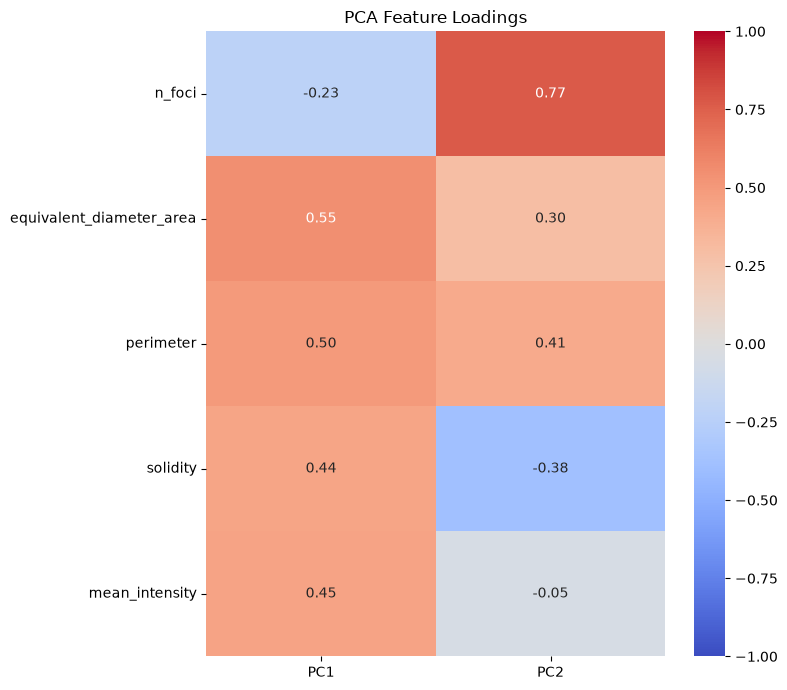

In [21]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

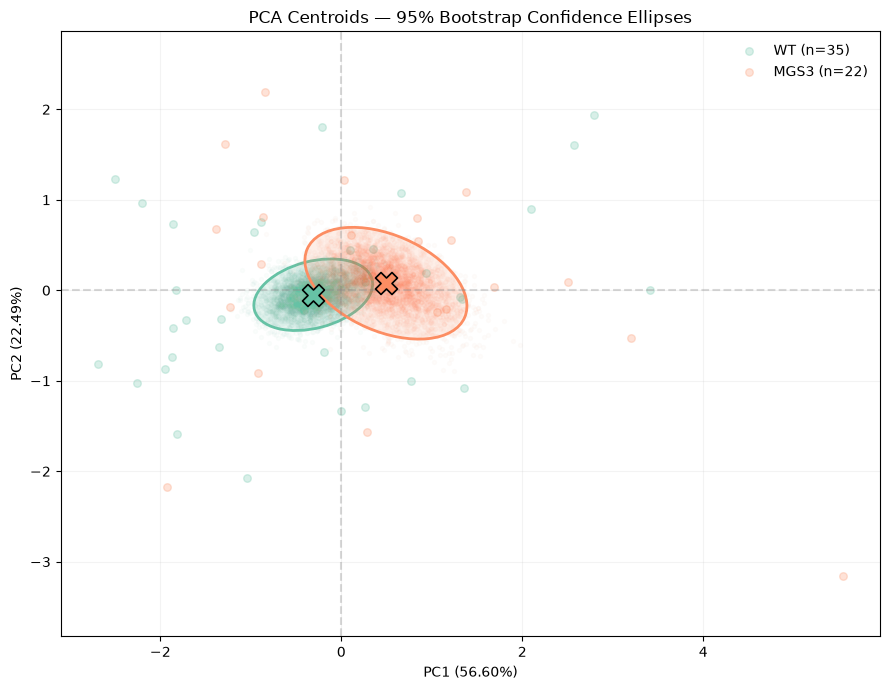

In [22]:
results_boot = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

In [23]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,2.270015,0.1140,0.039637,57,2
1,PERMDISP,0.002870,0.9586,NaN,57,2
